# Session 4 - What the model knows, and where it stops working

**Solutions.** Worked code and the numbers you should expect.

## What the model knows, and where it stops working

A model with a defensible cross-validated score can still be useless in
deployment, and the reason is almost never the score. Today: whether the signal
is real at all, what the model is actually using, and the question that matters
most for a QSAR model in practice — **which molecules is this prediction valid
for?**

**This session (2 h)**

1. y-scrambling: an empirical null for your pipeline
2. Residuals: where the model fails, and why these descriptors have a floor
3. Feature importance, and why two methods disagree
4. The applicability domain: what happens outside the training chemistry
5. Capstone, to hand in

In [1]:
import sys, warnings
sys.path.insert(0, "..")          # so that `import qsar_helpers` works
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from qsar_helpers import (load_fish, load_aquatic, xy, fold_error,
                          molecule_groups, score_table,
                          DESCRIPTOR_NOTES, TARGET_LABEL)

RNG = 0                            # one seed for the whole notebook
plt.rcParams.update({"figure.figsize": (6, 4), "figure.dpi": 110,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
print("pandas", pd.__version__)
import sklearn; print("scikit-learn", sklearn.__version__)

pandas 3.0.6
scikit-learn 1.9.1


In [2]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (KFold, RepeatedKFold, train_test_split,
                                     cross_val_score, cross_val_predict)
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, root_mean_squared_error

fish = load_fish()
X, y = xy(fish)
cv5 = KFold(5, shuffle=True, random_state=RNG)

## 1. Is there any signal? (y-scrambling)

The standard sanity check in QSAR, and a good habit everywhere: shuffle the
target, leaving the descriptor matrix untouched, and run the **entire** pipeline.
Any structure the procedure finds in shuffled data is structure it invented.

### EXERCISE 4.1

Cross-validate the random forest on the real target. Then build a null
distribution from 30 shuffles of `y`, plot it with the real score marked, and
report where the real score falls relative to the null.

*Runtime about two minutes.*

real      R2 = +0.603
scrambled R2 = -0.187 +- 0.040   (max -0.086)


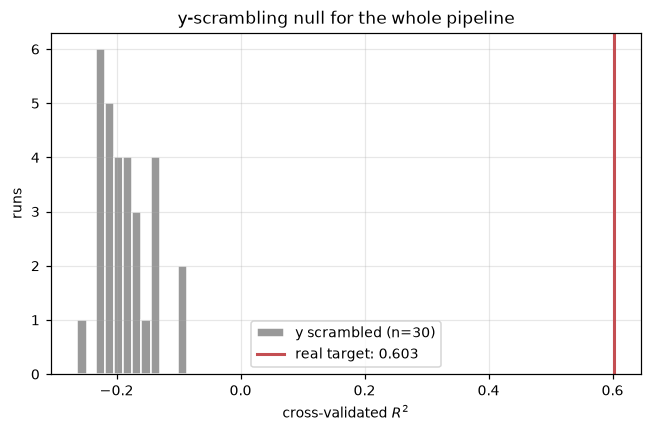

In [3]:
rf = RandomForestRegressor(n_estimators=200, random_state=RNG)
real = cross_val_score(rf, X, y, cv=cv5, scoring="r2").mean()

rng = np.random.default_rng(RNG)
null = np.array([cross_val_score(rf, X, rng.permutation(y), cv=cv5, scoring="r2").mean()
                 for _ in range(30)])

fig, ax = plt.subplots()
ax.hist(null, bins=12, color="#999999", edgecolor="white", label="y scrambled (n=30)")
ax.axvline(real, color="#C44E52", lw=2, label=f"real target: {real:.3f}")
ax.set_xlabel("cross-validated $R^2$"); ax.set_ylabel("runs")
ax.set_title("y-scrambling null for the whole pipeline")
ax.legend(); fig.tight_layout()

print(f"real      R2 = {real:+.3f}")
print(f"scrambled R2 = {null.mean():+.3f} +- {null.std():.3f}   (max {null.max():+.3f})")

The null sits at **-0.19 ± 0.04** and never gets above -0.09, while the real
score is +0.60. The signal is unambiguous.

Note where the null is centred: not at zero, but clearly *below* it. A flexible
model fitted to noise is actively worse than predicting the mean on held-out
data. That is why "my R<sup>2</sup> is positive, so there must be signal" is not
an argument — the comparison you need is against this distribution, and when
leakage is present the null moves up with the real score (try 4.1 again with the
feature-selection mistake from session 2 if you want to see it).

## 2. Residuals

### EXERCISE 4.2

Use `cross_val_predict` to get an out-of-fold prediction for every molecule.
Then:

1. Plot predicted against observed, with the 1:1 line.
2. Plot the residual against `MLOGP`. Is the error uniform across lipophilicity?
3. List the five molecules with the largest absolute residual, with their
   descriptor values. Any pattern?
4. Among the rows that share an identical descriptor vector with another row
   (session 2), compute the spread in measured LC50. What does this imply about
   the best RMSE any model on these six descriptors could achieve?

RMSE by MLOGP tertile:
   low  n=304  RMSE=1.031
   mid  n=301  RMSE=0.724
  high  n=303  RMSE=0.946

five largest absolute residuals:
      CIC0  SM1_Dz(Z)  GATS1i  NdsCH  NdssC  MLOGP  LC50  pred  resid
447  1.786      0.702   1.081      0      0 -1.265  8.13  3.15   4.98
259  4.785      1.263   1.471      1      4  2.749  9.61  5.54   4.07
237  2.031      0.872   1.475      0      1  0.202  6.42  2.65   3.77
287  3.514      0.134   1.070      1      0  3.315  7.81  4.10   3.71
182  4.810      0.693   1.420      0      2  5.426  2.55  6.11  -3.57

84 descriptor vectors occur more than once (217 rows)
mean within-group sd of LC50 : 0.320 log units
largest within-group range   : 3.086 log units
model RMSE overall           : 0.910 log units


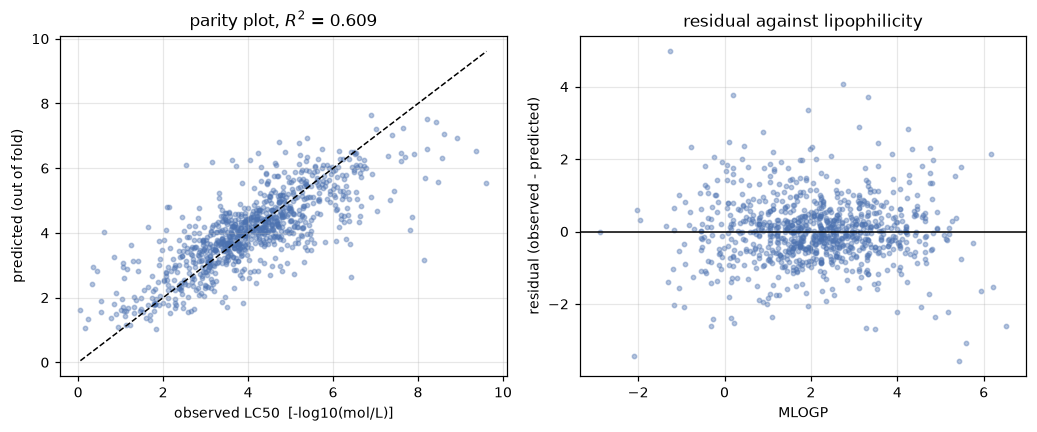

In [4]:
pred = cross_val_predict(RandomForestRegressor(n_estimators=200, random_state=RNG),
                         X, y, cv=cv5)
resid = y - pred

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
axes[0].scatter(y, pred, s=8, alpha=0.4, color="#4C72B0")
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "k--", lw=1)
axes[0].set_xlabel("observed " + TARGET_LABEL); axes[0].set_ylabel("predicted (out of fold)")
axes[0].set_title(f"parity plot, $R^2$ = {r2_score(y, pred):.3f}")
axes[1].scatter(X.MLOGP, resid, s=8, alpha=0.4, color="#4C72B0")
axes[1].axhline(0, color="k", lw=1)
axes[1].set_xlabel("MLOGP"); axes[1].set_ylabel("residual (observed - predicted)")
axes[1].set_title("residual against lipophilicity")
fig.tight_layout()

print("RMSE by MLOGP tertile:")
tert = pd.qcut(X.MLOGP, 3, labels=["low", "mid", "high"])
for lab, g in pd.Series(resid).groupby(tert, observed=True):
    print(f"  {lab:>4s}  n={len(g):3d}  RMSE={np.sqrt((g**2).mean()):.3f}")

print("\nfive largest absolute residuals:")
worst = np.argsort(-np.abs(resid))[:5]
print(pd.concat([X.iloc[worst].round(3),
                 pd.DataFrame({"LC50": y[worst].round(2),
                               "pred": pred[worst].round(2),
                               "resid": resid[worst].round(2)}, index=X.index[worst])],
                axis=1).to_string())

groups = molecule_groups(X)
gdf = pd.DataFrame({"g": groups, "y": y})
rep = gdf.groupby("g")["y"].agg(["size", "std", "min", "max"])
rep = rep[rep["size"] > 1]
print(f"\n{len(rep)} descriptor vectors occur more than once "
      f"({int(rep['size'].sum())} rows)")
print(f"mean within-group sd of LC50 : {rep['std'].mean():.3f} log units")
print(f"largest within-group range   : {(rep['max']-rep['min']).max():.3f} log units")
print(f"model RMSE overall           : {root_mean_squared_error(y, pred):.3f} log units")

Two things come out of this.

The residuals are not uniform, but not in the direction most people guess. RMSE
by `MLOGP` tertile is **1.03 (low) / 0.72 (mid) / 0.95 (high)** — the model does
*worst* on the least lipophilic third. And the five largest residuals are nearly
all large **under-predictions**: compounds measured as highly toxic (LC50 of 8.1,
9.6, 6.4, 7.8 on the -log10 scale) whose `MLOGP` is low or moderate, predicted
near 3-5.

That is a recognisable pattern in ecotoxicology rather than a modelling
artefact. Baseline narcosis sets a floor on toxicity as a function of
lipophilicity; compounds that act by a *specific* mechanism — binding a receptor
or inhibiting an enzyme — are far more toxic than their log P predicts, which
the field calls **excess toxicity**. A model whose dominant descriptor is `MLOGP`
reproduces the baseline and necessarily misses those compounds, and six bulk
descriptors carry nothing that would flag them. Worth asking the room: in which
direction does this model fail, and is that the safe direction for a screening
tool?

More fundamentally: rows with **identical descriptor vectors** differ in measured
LC50 by 0.32 log units on average, and by up to 3.1 log units in the worst case.
No model built on these six descriptors can distinguish those molecules — they
are literally the same input. That within-group spread is an irreducible floor
on achievable RMSE, and our model's RMSE of 0.91 is well above it, so the
descriptors are not yet the binding constraint. But it does bound what any
amount of modelling on this representation could deliver, which is the kind of
statement worth making before anyone proposes a neural network.

## 3. Feature importance, and two methods that disagree

### EXERCISE 4.3

Fit a random forest on 75% of the data. Compute

- the built-in `feature_importances_` (mean impurity decrease, computed on the
  **training** data), and
- `permutation_importance` on the **held-out** 25%, with 30 repeats.

Plot them side by side. Where do they disagree, and which would you trust for
the claim "descriptor X matters for toxicity"?

  feature  impurity (train)  permutation (test)  perm sd
    NdssC             0.026               0.012    0.004
     CIC0             0.093               0.031    0.012
    NdsCH             0.033               0.088    0.016
   GATS1i             0.114               0.097    0.023
SM1_Dz(Z)             0.171               0.235    0.040
    MLOGP             0.562               0.410    0.058


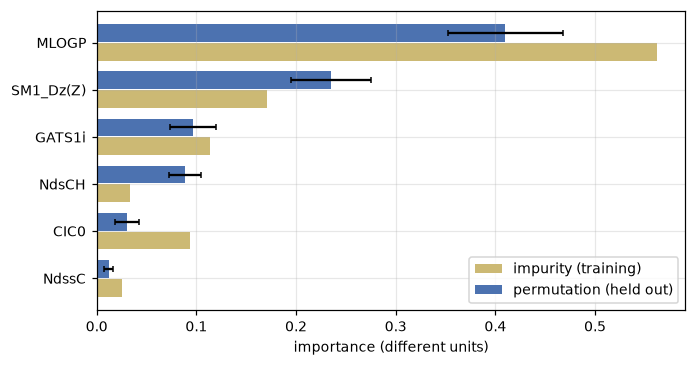

In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=RNG)
rf = RandomForestRegressor(n_estimators=500, random_state=RNG).fit(X_tr, y_tr)
pi = permutation_importance(rf, X_te, y_te, n_repeats=30, random_state=RNG, scoring="r2")

imp = pd.DataFrame({"feature": X.columns,
                    "impurity (train)": rf.feature_importances_,
                    "permutation (test)": pi.importances_mean,
                    "perm sd": pi.importances_std}).sort_values("permutation (test)")
print(imp.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.4, 3.4))
pos = np.arange(len(imp))
ax.barh(pos - 0.2, imp["impurity (train)"], height=0.38, label="impurity (training)", color="#CCB974")
ax.barh(pos + 0.2, imp["permutation (test)"], height=0.38, xerr=imp["perm sd"],
        label="permutation (held out)", color="#4C72B0", capsize=2)
ax.set_yticks(pos); ax.set_yticklabels(imp.feature)
ax.set_xlabel("importance (different units)")
ax.legend(); fig.tight_layout()

`MLOGP` dominates both rankings, which is what the narcosis mechanism predicts.
But the two methods disagree on the rest: impurity importance gives `NdsCH`
0.03 while permuting it on held-out data costs 0.09 of R<sup>2</sup>, and the
ordering of the middle features changes.

They measure different things. Impurity importance is computed on the training
data and is biased toward features with many distinct values — a feature with
500 unique values offers far more candidate split points than a 0-4 count, so it
accumulates impurity decrease even when it is partly fitting noise. Permutation
importance on held-out data asks a question you actually care about: how much
predictive performance is lost if this column is destroyed?

### EXERCISE 4.4 — correlated descriptors break both

Now switch to the aquatic dataset (`load_aquatic()`), where `TPSA(Tot)` and
`SAacc` are correlated at r = 0.86 — both are measures of polar surface.

1. Compute both importances there. Look at `TPSA(Tot)`, `SAacc` and `GATS1p`.
2. Drop `SAacc` entirely, refit, and re-score. What happens to the model's
   performance, and what happens to `TPSA(Tot)`'s importance?
3. Write one sentence stating what a permutation importance of ~0 means when the
   feature has a correlated partner in the matrix.

In [6]:
aqua = load_aquatic()
Xa, ya = xy(aqua)
print("corr(TPSA, SAacc) =", round(Xa[["TPSA(Tot)", "SAacc"]].corr().iloc[0, 1], 3))

Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xa, ya, test_size=0.25, random_state=RNG)
rfa = RandomForestRegressor(n_estimators=500, random_state=RNG).fit(Xa_tr, ya_tr)
pia = permutation_importance(rfa, Xa_te, ya_te, n_repeats=30, random_state=RNG, scoring="r2")
print("\n(1) full descriptor set")
print(pd.DataFrame({"feature": Xa.columns,
                    "impurity": rfa.feature_importances_,
                    "permutation": pia.importances_mean}).round(3).to_string(index=False))

print("\n(2) after dropping SAacc")
Xd = Xa.drop(columns="SAacc")
cv_a = KFold(5, shuffle=True, random_state=RNG)
full_cv = cross_val_score(RandomForestRegressor(n_estimators=500, random_state=RNG),
                          Xa, ya, cv=cv_a, scoring="r2").mean()
drop_cv = cross_val_score(RandomForestRegressor(n_estimators=500, random_state=RNG),
                          Xd, ya, cv=cv_a, scoring="r2").mean()
rfd = RandomForestRegressor(n_estimators=500, random_state=RNG).fit(
    Xd.loc[Xa_tr.index], ya_tr)
pid = permutation_importance(rfd, Xd.loc[Xa_te.index], ya_te, n_repeats=30,
                             random_state=RNG, scoring="r2")
print(f"CV R2 with all 8 descriptors : {full_cv:.3f}")
print(f"CV R2 without SAacc          : {drop_cv:.3f}")
print(pd.DataFrame({"feature": Xd.columns,
                    "impurity": rfd.feature_importances_,
                    "permutation": pid.importances_mean}).round(3).to_string(index=False))

# (3) A permutation importance near zero means "this model does not need this
#     column, given the others it has" -- not "this property is irrelevant to
#     the biology". With a correlated partner present, the information survives
#     the permutation and the importance is shared out between them, in a split
#     that depends on the fitting noise rather than on the chemistry.

corr(TPSA, SAacc) = 0.86

(1) full descriptor set
  feature  impurity  permutation
TPSA(Tot)     0.108        0.217
    SAacc     0.090        0.067
    H-050     0.030        0.029
    MLOGP     0.366        0.284
    RDCHI     0.187        0.103
   GATS1p     0.174        0.039
       nN     0.027       -0.005
    C-040     0.016        0.008

(2) after dropping SAacc
CV R2 with all 8 descriptors : 0.512
CV R2 without SAacc          : 0.501
  feature  impurity  permutation
TPSA(Tot)     0.114        0.190
    H-050     0.053        0.089
    MLOGP     0.380        0.274
    RDCHI     0.200        0.112
   GATS1p     0.192        0.050
       nN     0.037       -0.004
    C-040     0.023        0.021


Dropping a descriptor correlated at 0.86 with another leaves cross-validated
performance essentially unchanged — 0.512 with all eight descriptors, 0.501
without `SAacc`, a difference well inside the ±0.08 fold-to-fold spread — while
the importances rearrange. `H-050` goes from 0.029 to 0.089, and `TPSA(Tot)`
from 0.217 to 0.190: the model redistributes what it leans on, and the
redistribution does not even go to the dropped descriptor's closest partner.

So feature importance is a statement about **this fitted model on this
descriptor set**, not about mechanism. If the question is "does polar surface
area matter for *Daphnia* toxicity", importance rankings are not the instrument
that answers it.

## 4. The applicability domain

Cross-validation answers: how well does the model predict molecules *drawn from
the same pool* as the training molecules? That is rarely the deployment question.
In practice the model is used on a new chemical series — compounds more
lipophilic, larger, or differently substituted than anything in the training set.

### EXERCISE 4.5

Simulate that honestly on both datasets. Take the top quartile of `MLOGP` as the
test set and train on the remaining 75%. Compare with a random split of the
same size.

1. Do this for the fish dataset, reporting R<sup>2</sup> and RMSE for both splits.
2. Repeat for the aquatic dataset.
3. Compare the mean LC50 of the training and test portions. What systematic
   error do you expect, and in which direction?

fish: hold out MLOGP > 3.10  (n_test = 226)
   extrapolation : R2 = +0.037   RMSE = 1.195
   random split  : R2 = +0.607
   mean LC50 train 3.62 -> test 5.41;  mean prediction 4.91

aquatic: hold out MLOGP > 3.39  (n_test = 137)
   extrapolation : R2 = -0.657   RMSE = 1.649
   random split  : R2 = +0.489
   mean LC50 train 4.23 -> test 5.94;  mean prediction 4.81


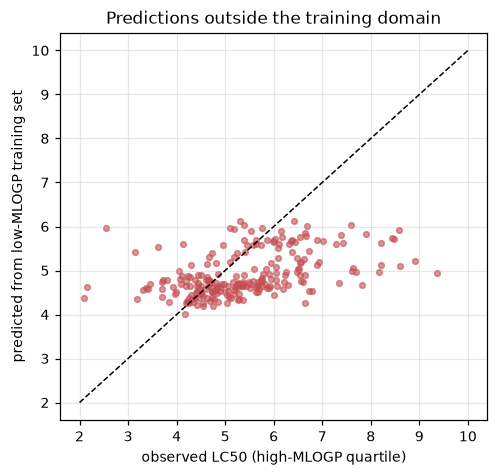

In [7]:
def extrapolation_test(Xd, yd, feature="MLOGP", q=0.75, label=""):
    thr = np.quantile(Xd[feature], q)
    hi = (Xd[feature] > thr).to_numpy()
    rf = RandomForestRegressor(n_estimators=500, random_state=RNG).fit(Xd[~hi], yd[~hi])
    p = rf.predict(Xd[hi])
    rnd = []
    for s in range(10):
        tr, te = train_test_split(np.arange(len(Xd)), test_size=float(hi.mean()), random_state=s)
        m = RandomForestRegressor(n_estimators=500, random_state=RNG).fit(Xd.iloc[tr], yd[tr])
        rnd.append(r2_score(yd[te], m.predict(Xd.iloc[te])))
    print(f"{label}: hold out {feature} > {thr:.2f}  (n_test = {hi.sum()})")
    print(f"   extrapolation : R2 = {r2_score(yd[hi], p):+.3f}   RMSE = {root_mean_squared_error(yd[hi], p):.3f}")
    print(f"   random split  : R2 = {np.mean(rnd):+.3f}")
    print(f"   mean LC50 train {yd[~hi].mean():.2f} -> test {yd[hi].mean():.2f};"
          f"  mean prediction {p.mean():.2f}")
    return hi, p

hi_f, pred_f = extrapolation_test(X, y, label="fish")
print()
hi_a, pred_a = extrapolation_test(Xa, ya, label="aquatic")

fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.scatter(y[hi_f], pred_f, s=14, alpha=0.6, color="#C44E52")
ax.plot([2, 10], [2, 10], "k--", lw=1)
ax.set_xlabel("observed LC50 (high-MLOGP quartile)")
ax.set_ylabel("predicted from low-MLOGP training set")
ax.set_title("Predictions outside the training domain")
fig.tight_layout()

This is the largest effect in the whole course. On the fish data,
cross-validated R<sup>2</sup> of 0.61 becomes **0.04** when the test molecules are
simply more lipophilic than the training molecules. On the aquatic data it
becomes **-0.66** — markedly worse than predicting the training mean.

The mechanism is visible in the parity plot: the forest cannot predict outside
the range of target values it was trained on, because every prediction is an
average of training leaves. Mean LC50 rises from 3.62 to 5.41 across the split,
and the predictions stay near the training range, so the model is systematically
**under-predicting toxicity** — exactly the direction that matters for a safety
assessment.

Note also that the choice of splitting descriptor matters: holding out the top
quartile of `CIC0` instead gives R<sup>2</sup> = 0.28, not 0.04. "Out of domain"
is not one thing.

### EXERCISE 4.6 — an applicability-domain indicator

A model used in practice should refuse to answer, or flag its answer, for
molecules unlike its training set. Build the simplest such indicator.

1. Fit `NearestNeighbors` on the **scaled** training descriptors. For each test
   molecule compute the mean distance to its 5 nearest training molecules.
2. Split the test molecules into quartiles of that distance and report the RMSE
   in each quartile.
3. Verify the indicator also flags the high-`MLOGP` molecules from 4.5.

test molecules binned by mean distance to 5 nearest training molecules
    nearest  n= 57  mean distance 0.27  RMSE 0.512
       near  n= 57  mean distance 0.54  RMSE 0.772
        far  n= 56  mean distance 0.82  RMSE 0.901
   farthest  n= 57  mean distance 1.51  RMSE 1.428

mean distance, random held-out molecules      : 0.79
mean distance, high-MLOGP held-out molecules  : 1.61


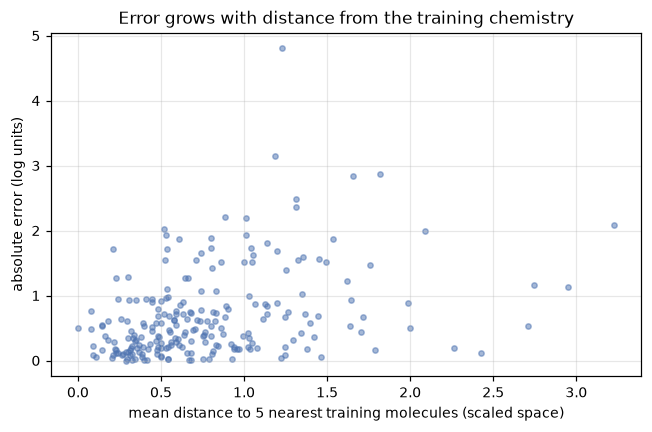

In [8]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=RNG)
sc = StandardScaler().fit(X_tr)
nn = NearestNeighbors(n_neighbors=5).fit(sc.transform(X_tr))
dist = nn.kneighbors(sc.transform(X_te))[0].mean(axis=1)

rf = RandomForestRegressor(n_estimators=500, random_state=RNG).fit(X_tr, y_tr)
err = np.abs(y_te - rf.predict(X_te))

q = pd.qcut(dist, 4, labels=["nearest", "near", "far", "farthest"])
print("test molecules binned by mean distance to 5 nearest training molecules")
for lab, g in pd.DataFrame({"err": err, "d": dist}).groupby(q, observed=True):
    print(f"  {lab:>9s}  n={len(g):3d}  mean distance {g.d.mean():.2f}  "
          f"RMSE {np.sqrt((g.err**2).mean()):.3f}")

sc_all = StandardScaler().fit(X[~hi_f])
nn_all = NearestNeighbors(n_neighbors=5).fit(sc_all.transform(X[~hi_f]))
d_out = nn_all.kneighbors(sc_all.transform(X[hi_f]))[0].mean(axis=1)
print(f"\nmean distance, random held-out molecules      : {dist.mean():.2f}")
print(f"mean distance, high-MLOGP held-out molecules  : {d_out.mean():.2f}")

fig, ax = plt.subplots()
ax.scatter(dist, err, s=12, alpha=0.5, color="#4C72B0")
ax.set_xlabel("mean distance to 5 nearest training molecules (scaled space)")
ax.set_ylabel("absolute error (log units)")
ax.set_title("Error grows with distance from the training chemistry")
fig.tight_layout()

A crude indicator, and it works: error rises across the distance quartiles, and
the high-`MLOGP` molecules sit far outside the distances seen in a random
held-out sample. A deployed QSAR model should report this alongside every
prediction; the OECD validation principles require a defined applicability
domain for exactly this reason.

## 5. Capstone — to hand in

You have a second dataset you have barely used: `load_aquatic()`, 546 molecules,
eight descriptors, LC50 toward *Daphnia magna*. Treat it as a new project and
apply everything from the four sessions.

**Deliverable: one notebook plus a methods paragraph of at most 250 words.**

Required content.

1. **Baseline.** The dummy's R<sup>2</sup> and RMSE, and the RMSE as a
   fold-error in concentration.
2. **A tuned model, selected honestly.** Choose among at least three model
   families with at least three hyperparameter settings each. Report either a
   nested-CV estimate or a flat estimate explicitly labelled as an upper bound,
   and state how many configurations you tried.
3. **A spread, not a point.** Repeated cross-validation, mean ± sd, and a
   sentence on whether your chosen model is distinguishable from the runner-up.
4. **Leakage audit.** State for each data-dependent step where it sits relative
   to the resampling loop. Report the number of rows sharing an identical
   descriptor vector and what you did about it.
5. **A y-scrambling null** for your final pipeline.
6. **An applicability domain.** One extrapolation experiment of your choice, one
   domain indicator, and a statement of which molecules your model should not be
   used for.
7. **One honest negative result.** Something you expected to matter that did
   not, with the number that shows it.

The methods paragraph should be written so that a reader could reproduce your
estimate and would not be surprised by your model's performance in deployment.

Marking weights the audit and the applicability domain as heavily as the
performance. A submission reporting R<sup>2</sup> = 0.50 with a correct audit
scores above one reporting 0.60 without.

In [9]:
# Reference figures for the capstone (instructor copy).
# 5-fold x 5-repeat CV on the aquatic dataset:
#     dummy          R2 = -0.008 +- 0.011     RMSE 1.663  (factor 46)
#     ridge(alpha=1) R2 =  0.458 +- 0.058     RMSE 1.216  (factor 16)
#     kNN(k=5)       R2 =  0.487 +- 0.082
#     HistGB         R2 =  0.509 +- 0.094
#     RF(500)        R2 =  0.533 +- 0.083     RMSE 1.125  (factor 13)
# Extrapolation, top MLOGP quartile held out: R2 = -0.657 (random split 0.489)
# Only 16 of the 546 rows share a descriptor vector with another row here
# (against 217 of 908 in the fish data), so a grouped split makes no measurable
# difference: the measured gap is +0.000 for a random forest and +0.016 for
# kNN(k=1). That is a legitimate answer to requirement 7, provided the student
# reports the count and the measured gap.
aqua = load_aquatic()
Xa, ya = xy(aqua)
print(aqua.shape)
print(f"{len(set(molecule_groups(Xa)))} distinct descriptor vectors in {len(Xa)} rows")
aqua.describe().T.round(2)

(546, 9)
537 distinct descriptor vectors in 546 rows


           count   mean    std   min    25%    50%    75%     max
TPSA(Tot)  546.0  48.47  46.76  0.00  15.79  40.46  70.02  347.32
SAacc      546.0  58.87  68.17  0.00  11.00  42.68  77.49  571.95
H-050      546.0   0.94   1.62  0.00   0.00   0.00   1.00   18.00
MLOGP      546.0   2.31   1.74 -6.45   1.23   2.27   3.39    9.15
RDCHI      546.0   2.49   0.81  1.00   1.98   2.34   2.91    6.44
GATS1p     546.0   1.05   0.40  0.28   0.74   1.02   1.27    2.50
nN         546.0   1.00   1.40  0.00   0.00   1.00   2.00   11.00
C-040      546.0   0.35   0.81  0.00   0.00   0.00   0.00   11.00
LC50       546.0   4.66   1.67  0.12   3.60   4.52   5.61   10.05

## Reporting checklist

What a defensible supervised-learning result contains. Keep this; it applies
well beyond QSAR.

1. The baseline, in the same units and on the same folds.
2. The performance metric in units someone in the field can interpret — a
   fold-error, not only an R<sup>2</sup>.
3. An estimate with a spread, from repeated resampling, not a single split.
4. The resampling scheme, including the grouping variable if the rows are not
   independent.
5. Every data-dependent step located relative to the resampling loop.
6. The number of model configurations tried, and whether selection was nested.
7. An empirical null for the whole pipeline.
8. The applicability domain, and the performance drop outside it.
9. At least one thing you checked that turned out not to matter.